# OISST Peru: temporal extremes to genealogy

Registered NOAA OISST v2.1 AVHRR-only SST, 1991–2025, reference 1991–2020. The temporal reference has prior scientific approval. Dynamic and spatial summaries are reproduced outputs pending scientific review. The tutorial contrasts fixed and detrended baselines using identical definitions.

Read [the tutorial guide](../docs/TUTORIALS.md) for inputs, units and configuration. Saved outputs can be read without data. Re-execution requires the optional `examples/requirements.txt` and, for real cases, the inputs in [Data](../docs/DATA.md). No download is triggered by this notebook.

## Configuration of these saved outputs

| Choice | Value |
|---|---|
| Publication | 0.1.0 |
| Source | https://data.source.coop/ocean-icechunks/noaa-oisst/oisst.icechunk#daily |
| Reference period | 1991-01-01 through 2020-12-31 |
| Baseline / fit mode | fixed_climatology / retrospective |
| Seasonal pooling / smoothing (days) | 11 / 31 |
| Percentile estimator | hyndman_fan_7 |
| Minimum samples | 264 |
| Leap policy | hobday_366_interp |
| Within-reference correction | none |
| Representative tail / percentile / comparator | upper / 90.0 / > |
| Minimum duration / temporal gap (days) | 5 / 2 |
| Missing / join policy | as_non_exceedance / qualify_then_join |
| Declared day | native |
| Support / spatial dimensions | surface / lat, lon |
| Domain / measure | ocean / area |
| Review status | temporal reference approved; dynamic and spatial summaries pending scientific review |

The representative definition is supplemented by the explicitly shown MCS/dynamic or TX/TN joint comparisons where present. Tracking configuration appears in its recipe cell. Full portable specs and checksums are in `report.json` and [the saved run record](../docs/run_records/oisst.json).


In [1]:
import os
import sys
from pathlib import Path

EXAMPLES = Path.cwd() if (Path.cwd() / "_data.py").exists() else Path.cwd() / "examples"
sys.path.insert(0, str(EXAMPLES))
%matplotlib inline
data_dir = Path(os.environ.get("XHW_DATA_DIR", EXAMPLES.parent / "data"))
output_dir = Path(os.environ.get("XHW_OUTPUT_DIR", EXAMPLES.parent / "outputs")) / "oisst"

## Named configurations for the example

`mhw` and the other names below are local Python aliases containing complete
DefinitionSpec values, not extra arguments or automatic presets in `xhw.detect`.
Inspect them with `.to_dict()`. The loader still declares the baseline, reference
period and grid. The volume example keeps its potential-temperature definition.


In [2]:
from profiles import example_profiles

definitions = example_profiles()
mhw, mcs = definitions["mhw"], definitions["mcs"]
ahw_tx90, ahw_tn90 = definitions["ahw_tx90"], definitions["ahw_tn90"]
ahw_txtn90 = definitions["ahw_txtn90"]
ahw_tx_then_tn90 = definitions["ahw_tx_then_tn90"]
{name: (spec.phenomenon, spec.profile) for name, spec in definitions.items()}


{'mhw': ('mhw', 'hobday2016'),
 'mcs': ('mcs', 'schlegel2021'),
 'ahw_tx90': ('ahw', 'perkins2013_tx90'),
 'ahw_tn90': ('ahw', 'perkins2013_tn90'),
 'ahw_txtn90': ('ahw', 'xhw_txtn90'),
 'ahw_tx_then_tn90': ('ahw', 'xhw_tx_then_tn90')}

In [3]:
from dataclasses import replace
from pathlib import Path

from _data import load_oisst, marine_definition
from _report import lineage_catalog_status, spatial_summary, temporal_summary, write_report
from plotting import (
    frequency_figure,
    genealogy_figure,
    largest_event,
    metrics_figure,
    sequence_figure,
    series_figure,
)

import xhw

print(f"Publication API: xHW {xhw.__version__}")

## Open and verify the registered daily SST subset

Read only local registered data. The SHA-256 check rejects a different file before analysis. The input selection is 12°S–4°S, 82°W–77°W; opening and loading are eager here.

In [4]:
raw, grid, baseline, definition = load_oisst(data_dir)
# Alias of the complete, case-specific definition.
mhw = definition
grid.check(raw)
print("NOAA OISST v2.1; Peru 1991–2025; reference 1991–2020; registered SHA-256 verified.")
prepared = xhw.interpolate_gaps(
    raw, variable="sst", grid=grid, max_days=2, max_filled_fraction=0.05
)

NOAA OISST v2.1; Peru 1991–2025; reference 1991–2020; registered SHA-256 verified.


## Marine heatwaves and cold spells use distinct percentile tails

MHW uses strict P90 exceedance; MCS uses strict P10 under-threshold comparison. Both use 11-day pooling, 31-day smoothing, type 7, minimum five days and gaps up to two days, qualifying runs before joining. Frequency uses valid-day support.

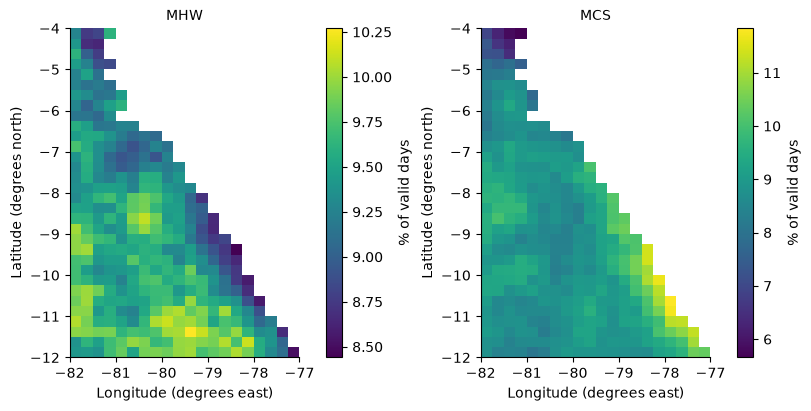

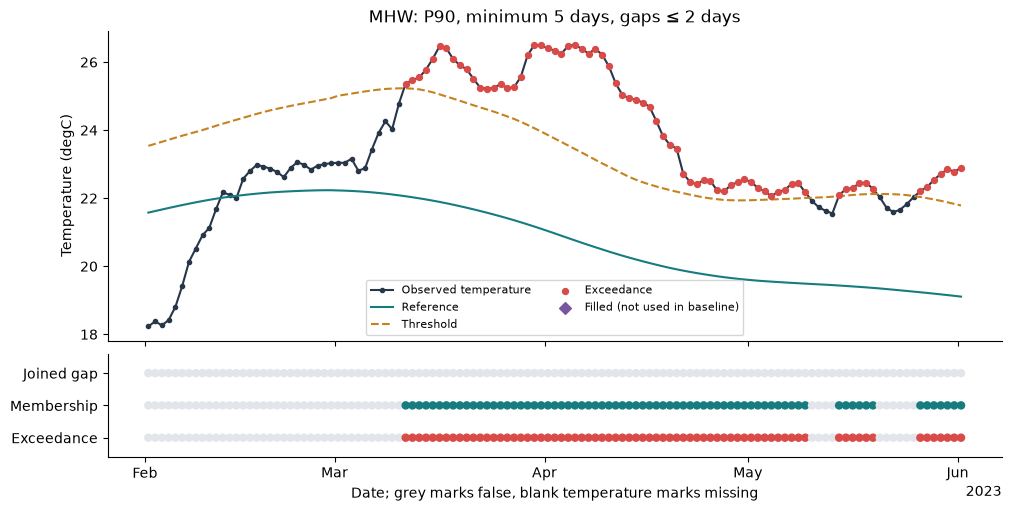

In [5]:
masks, catalogs, metrics = {}, {}, {}
for name, detector in (("MHW", definition), ("MCS", marine_definition(cold=True))):
    fitted = xhw.fit_baseline(
        prepared, variable="sst", grid=grid, baseline=baseline, definition=detector
    )
    fitted.check_invariants()
    masks[name] = xhw.detect(
        prepared, variable="sst", grid=grid, definition=detector, baseline_result=fitted
    )
    masks[name].check_invariants()
    catalogs[name] = xhw.build_catalog(masks[name], analysis_mode="retrospective")
    catalogs[name].check_against(masks[name])
    metrics[name] = temporal_summary(masks[name], catalogs[name])
mask = masks["MHW"]
figure = frequency_figure(masks, output_dir)
figure = series_figure(
    raw,
    mask,
    variable="sst",
    selection={"lat": 15, "lon": 10},
    period=("2023-02-01", "2023-06-01"),
    output_dir=output_dir,
)

**Reading these figures.** Temperature panels show observed values, reference, threshold and exceedances, with separate temporal-membership/gap rows. A diamond identifies a filled value; a gap in the raw line identifies the missing observation. Temperature units appear on the axis. An exceedance is not automatically a persistent event.

Frequency maps show the percentage of occupied valid days, with both numerator and denominator restricted to valid support. Outside-domain cells are blank. Panels have individual scales; compare colorbar values rather than color alone. Differences between methods/profiles are not proof of greater scientific skill.

## Compare the same definition with a retrospective detrended baseline

Only the baseline method changes to detrended (degree 1, three harmonics). Both are retrospective; neither is labelled superior. Jaccard uses jointly valid cell-days as support and membership union as denominator.

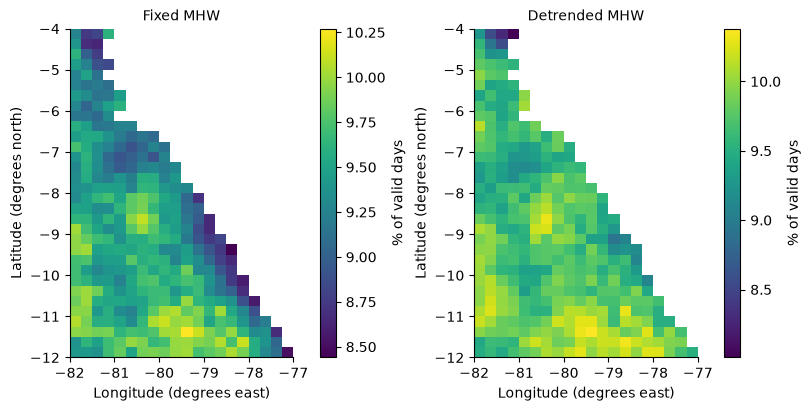

In [6]:
dynamic = replace(baseline, method="detrended")
fitted_dynamic = xhw.fit_baseline(
    prepared, variable="sst", grid=grid, baseline=dynamic, definition=mhw
)
fitted_dynamic.check_invariants()
dynamic_mask = xhw.detect(
    prepared, variable="sst", grid=grid, definition=mhw, baseline_result=fitted_dynamic
)
dynamic_mask.check_invariants()
dynamic_catalog = xhw.build_catalog(dynamic_mask, analysis_mode="retrospective")
dynamic_catalog.check_against(dynamic_mask)
metrics["detrended"] = temporal_summary(dynamic_mask, dynamic_catalog)
common_valid = mask.dataset.valid & dynamic_mask.dataset.valid
a, b = mask.dataset.event_membership, dynamic_mask.dataset.event_membership
union = int(((a | b) & common_valid).sum())
metrics["fixed_detrended_jaccard"] = float(((a & b) & common_valid).sum()) / union if union else 1.0
figure = frequency_figure(
    {"Fixed MHW": mask, "Detrended MHW": dynamic_mask}, output_dir, name="baseline_comparison"
)

**Reading these figures.** Frequency maps show the percentage of occupied valid days, with both numerator and denominator restricted to valid support. Outside-domain cells are blank. Panels have individual scales; compare colorbar values rather than color alone. Differences between methods/profiles are not proof of greater scientific skill.

## Track event-membership patches; the default recipe would not track

The default recipe does not track. This explicit recipe uses event membership, face-connected patches at least 5% of ocean area, any positive overlap and minimum five-day tracks. A retained patch can still have track ID zero if it is too short.

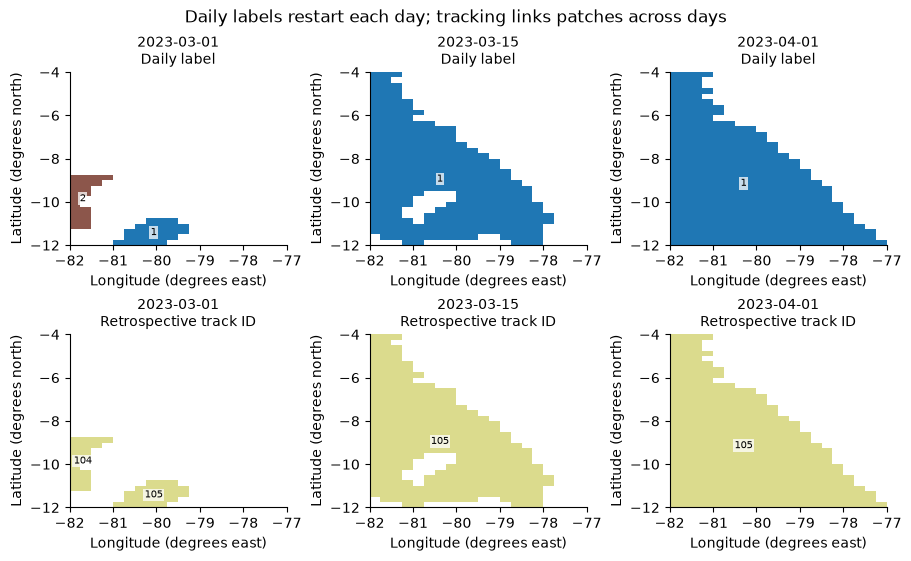

In [7]:
recipe = xhw.SpatialRecipe(
    input_layer="event_membership",
    steps=(
        xhw.RecipeStep.segment(
            footprint=xhw.Footprint.connected(1), min_area=xhw.MinArea.default()
        ),
        xhw.RecipeStep.track(min_overlap=0.0, max_gap_days=0, min_duration_days=5),
    ),
)
objects = xhw.build_objects(mask, recipe=recipe, analysis_mode="retrospective")
objects.check_invariants()
objects.check_against(mask)
figure = sequence_figure(objects, ["2023-03-01", "2023-03-15", "2023-04-01"], output_dir)

**Reading these figures.** Top row: daily labels. Bottom: retrospective tracker IDs, annotated with actual numbers. Background and invalid support are blank; consult the validity mask to distinguish them. IDs are categorical, not magnitudes, and palettes can repeat. For the volume case this is explicitly the first retained depth.

## Derive branches and spacetime events with area-weighted intensity

Intensity is temperature minus reference. Sizes and means are area weighted. The graph includes all patch labels; short components can prevent qualified EventCatalog export in 0.1.0. That constraint is recorded, while graph invariants are checked.

Catalog export constraint: 18 graph components are shorter than 5 days. Use graph.dataset for these components.


,event_number,event_duration_days,event_n_branches,event_n_splits,event_n_merges
spacetime_event,,,,,
0,1,1,1,0,0
1,2,5,1,0,0
2,3,5,1,0,0
3,4,14,1,0,0
4,5,15,1,0,0


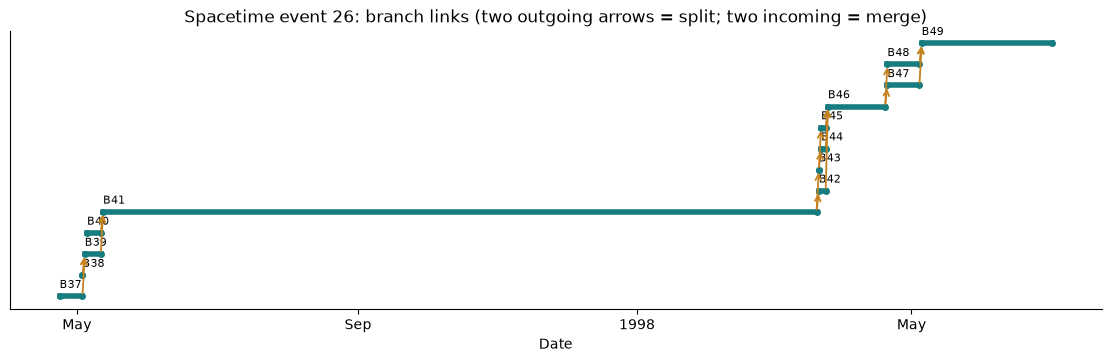

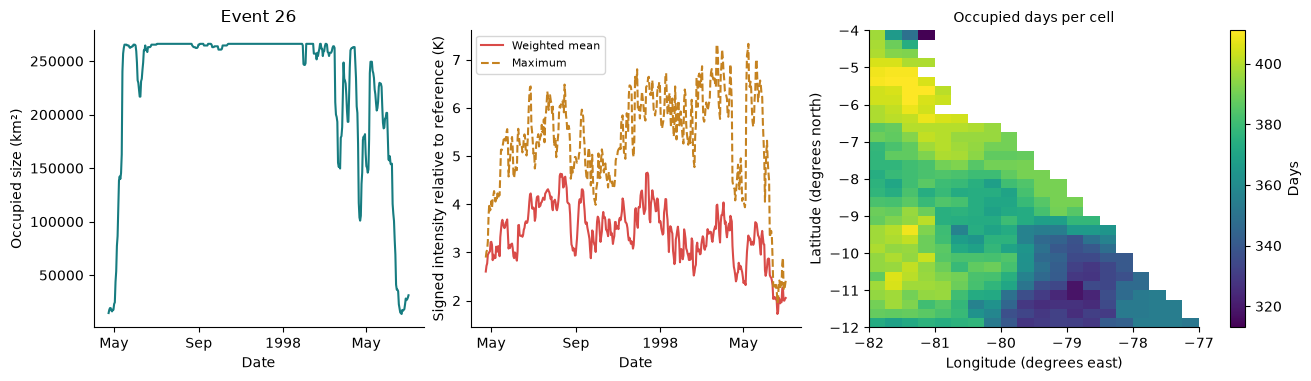

In [8]:
graph = xhw.build_lineage(objects, field=mask.intensity(), weighted=True)
graph.check_invariants()
graph.check_against(objects)
metrics["lineage_catalog_export"] = lineage_catalog_status(graph, mask)
event = largest_event(graph)
figure = genealogy_figure(graph, event, output_dir)
metrics_figure(graph, objects, event, output_dir)
del figure
metrics["spatial"] = spatial_summary(objects, graph)
metrics["largest_size_time_event"] = int(event)

graph.dataset[
    ["event_number", "event_duration_days", "event_n_branches", "event_n_splits", "event_n_merges"]
].isel(spacetime_event=slice(0, 5)).to_dataframe()

**Reading these figures.** Teal segments are branches and amber arrows are qualifying parent/child links. Two outgoing links indicate a split; two incoming a merge. Real diagrams mark when only the first 18 branches are displayed. This does not establish causality.

The selected event has size in km² (surface) or km³ (volume), weighted mean and maximum signed intensity relative to reference in K, and occupied days per cell. The volume map is a first-level slice. Peak size, size-time and footprint are different quantities; these figures do not represent all events at once.

## Preserve the distinction between reproduced output and scientific approval

Temporal-reference approval is retained separately from pending review of dynamic, spatial and lineage summaries. No scientific approval is inferred from execution.

In [9]:
report = write_report(
    output_dir,
    "oisst",
    metrics,
    grid=grid,
    baseline=baseline,
    definition=mhw,
    recipe=recipe,
    graph=graph,
    review=("temporal reference approved; dynamic and spatial summaries pending scientific review"),
    extra={
        "selection": "Peru: latitude -12 to -4; longitude -82 to -77; 1991–2025",
        "dynamic_baseline": dynamic.to_dict(),
        "comparison_denominator": "union of membership on jointly valid cell-days",
        "common_valid_cell_days": int(common_valid.sum()),
        "source_resolution_degrees": 0.25,
    },
)

{
  "MHW": {
    "events": 16702,
    "exceedance_cell_days": 480043,
    "event_cell_days": 422215,
    "joined_cell_days": 3926,
    "valid_cell_days": 4461616,
    "filled_cell_days": 0,
    "max_duration_days": 412
  },
  "MCS": {
    "events": 27003,
    "exceedance_cell_days": 498688,
    "event_cell_days": 402450,
    "joined_cell_days": 4146,
    "valid_cell_days": 4461616,
    "filled_cell_days": 0,
    "max_duration_days": 311
  },
  "detrended": {
    "events": 16765,
    "exceedance_cell_days": 490980,
    "event_cell_days": 433288,
    "joined_cell_days": 4129,
    "valid_cell_days": 4461616,
    "filled_cell_days": 0,
    "max_duration_days": 410
  },
  "fixed_detrended_jaccard": 0.9162562017717748,
  "lineage_catalog_export": {
    "status": "not exportable as qualified EventCatalog",
    "short_components": 18,
    "reason": "qualified events shorter than min_duration_days"
  },
  "spatial": {
    "patches": 2956,
    "tracks": 118,
    "branches": 279,
    "spacetime_e

## Interpretation and provenance

Inspect the executed report and [metrics guide](https://github.com/DanielCamarena/xhw/blob/main/docs/METRICS.md). Keep domain, grid, reference, tail, missing policy, persistence, connectivity and overlap denominator attached to these numbers. Genealogy is not attribution. Figures are produced by xarray/Matplotlib, not a native xHW graphics API.

In [10]:
{
    "review_status": report["review_status"],
    "versions": report["versions"],
    "source_checksum": report["source"]["fields"]["checksum"],
}

{'review_status': 'temporal reference approved; dynamic and spatial summaries pending scientific review',
 'versions': {'xhw': '0.1.0',
  'numpy': '2.5.4',
  'xarray': '2026.7.0',
  'scipy': '1.16.3',
  'matplotlib': '3.11.2',
  'h5netcdf': '1.8.1',
  'nbformat': '5.11.1',
  'nbclient': '0.11.0'},
 'source_checksum': 'sha256:014bfb6556fb29d8ef3b67fef7ae878e2fc1e5ea73c3b825d88b9055cbd4cbb9'}

## Explore already computed products

Install `examples/requirements-interactive.txt` in this kernel, then use date, layer,
event/branch and cell controls. Map zoom and pan use the mouse. Date and cell sliders
update on release. Disabled event controls mean that the selected case has temporal
products only. TX+TN temperature panels show the first daily component.

The controls do not fit baselines or rerun detection/tracking. Static figures and tables
above remain readable on GitHub; these controls need a live Jupyter kernel.


In [11]:
from exploration import explorer

cases = {"Fixed MHW": (mask, objects, graph),
         "MCS (temporal products)": (masks["MCS"], None, None),
         "Detrended MHW (temporal products)": (dynamic_mask, None, None)}
explorer(cases)
